# 6. Streets: segments, crashes per road-km, heat along the street

Street analysis needs care about what a "street" is. In an OSMnx graph a two-way street is two
directed edges; counting both would double its length. urbanweave builds **physical segments**:
reciprocal edges of the same OSM way become one segment, while a divided road's two carriageways
stay two (they are two physical roadways). **Intersections** are nodes where three or more physical
segments meet.

The graph here is Riverton's, built offline in the shape OSMnx produces; with network access,
`osm_streets(place=...)` fetches a real one.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import urbanweave as uw

import tutorial_data as td          # Riverton, the synthetic town these tutorials use
from svgmap import Map              # small static SVG maps
from tutorial_data import show      # prints reports compactly
import diagrams                     # schematic figures of the concepts

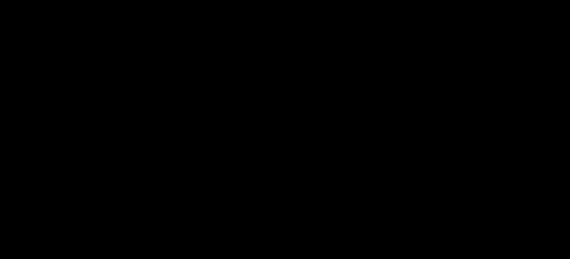

In [2]:
diagrams.street_graph()

In [3]:
import tempfile, os
from urbanweave import streets as uws

districts = td.districts()
crashes = td.crashes()
heat = td.heat()
graph_path = os.path.join(tempfile.mkdtemp(), "riverton.graphml")
td.save_street_graph(graph_path)

segments = uws.osm_streets(graphml=graph_path)                                  # physical (default)
directed = uws.osm_streets(graphml=graph_path, representation="directed")
nodes = uws.osm_intersections(graphml=graph_path)
print(len(directed), "directed edges ->", len(segments), "physical segments;", len(nodes), "intersections")
print("street length:", round(segments["length_m"].sum() / 1000, 2), "km (directed edges would say",
      round(directed["length_m"].sum() / 1000, 2), "km)")

424 directed edges -> 224 physical segments; 113 intersections
street length: 56.02 km (directed edges would say 106.02 km)


In [4]:
segments[segments["name"] == "Main Blvd"][["target_id", "name", "oneway", "edges", "length_m"]].head(4)

,target_id,name,oneway,edges,length_m
9,5-14-0,Main Blvd,True,5-14-0,250.894994
26,14-5-0,Main Blvd,True,14-5-0,250.894994
27,14-23-0,Main Blvd,True,14-23-0,250.894994
44,23-14-0,Main Blvd,True,23-14-0,250.894994


In [5]:
nodes["degree"].value_counts().sort_index()

degree
3    34
4    68
6    11
Name: count, dtype: int64

The intersections on Main Blvd have degree 6: two avenues plus two carriageways on each side.

## Crashes onto streets

`nearest_segment` attaches each crash to its nearest physical segment, within an explicit
distance. A crash farther than 25 m from every street (in a yard, a car park) is reported, not
forced onto a street.

In [6]:
m = uw.match(crashes, segments, "nearest_segment", source_id="crash_id", max_distance=25)
per_street = uw.aggregate(m, None, [uw.count(as_="crashes", fill_empty=0), uw.sum("persons_injured", as_="injured", fill_empty=0)])
show(m.report["sources"]["unmatched"])

{
 "beyond_max_distance": {
  "count": 22,
  "sample": ["C0560", "C0561", "C0562", "C0564", "C0565", "C0566", "C0568", "C0569", "C0571", "C0576"]
 }
}


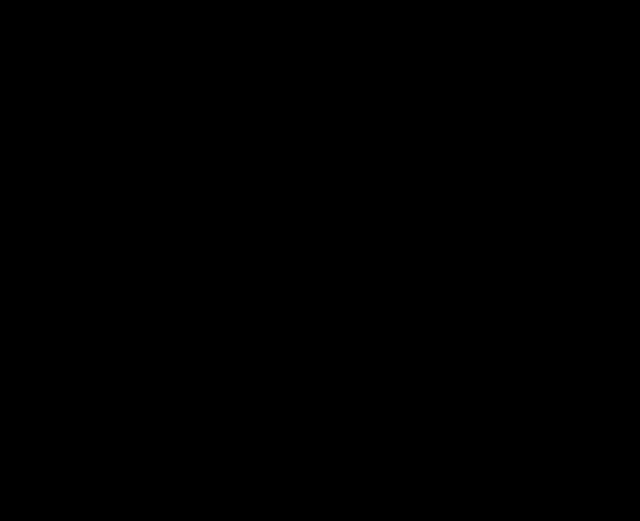

In [7]:
(Map("Crashes per street segment")
 .lines(per_street, "crashes", legend="crashes per segment", width=3.2, classes=5, tooltip=["name", "injured"])
 .dots(crashes.loc[crashes["crash_id"].isin(m.report["sources"]["unmatched"]["beyond_max_distance"]["sample"])], radius=3)
 .outline(districts, label="name", width=1)
 .note("Dots: a sample of the crashes more than 25 m from any street."))

## Crashes per road-km, by district

To compare districts fairly, divide crashes by the length of street in each district. A street
crossing a district boundary is split by length (`length_weighted`), and a street lying exactly on
a boundary is given to one district only (`shared_boundary="lowest_target_id"`). The density's
denominator is the overlapping length, so the result is crashes per road-km.

In [8]:
m2 = uw.match(per_street, districts, "length_weighted", target_id="district_id", shared_boundary="lowest_target_id")
density = uw.aggregate(m2, None, [
    uw.sum("crashes", as_="crashes"),
    uw.density("crashes", as_="crashes_per_road_km", denominator="overlap_length"),
])
density[["name", "crashes", "crashes_per_road_km"]].round(2)

,name,crashes,crashes_per_road_km
0,Northgate,111.57,9.21
1,Old Town,204.53,21.82
2,Eastfield,91.78,8.11
3,Mill District,76.9,6.44
4,Riverside,93.22,8.27


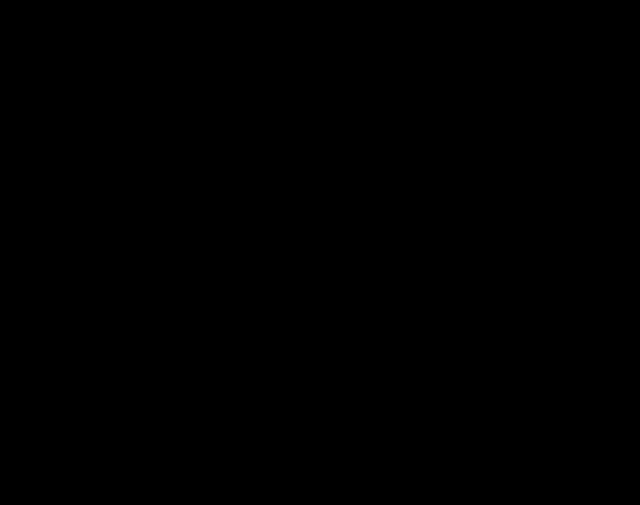

In [9]:
(Map("Crashes per road-km")
 .fill(density, "crashes_per_road_km", legend="crashes per km of street", classes=5)
 .lines(segments, width=0.8)
 .outline(districts, label="name"))

## Heat along the streets

How hot is it where people walk? `split_lines` cuts the streets at district boundaries into pieces
with stable IDs (`street|district`), `along_lines` averages the UTCI raster along each piece by the
length of street in each cell, and `reduce` pools the pieces by district with `ratio_of_sums`: the
total of UTCI × metres over the total valid metres. Pooling sums, not averaging averages, weights
each district by its street length. Pieces in the sensor gap contribute no valid length.

Streets along the town's southern edge lie exactly on the raster's edge. A cell owns its west and
north edges, so those streets belong to cells outside the raster: they have no valid length and a
missing mean (piece `1-10-0|MD` below), rather than being counted in two cells or in none
inconsistently.

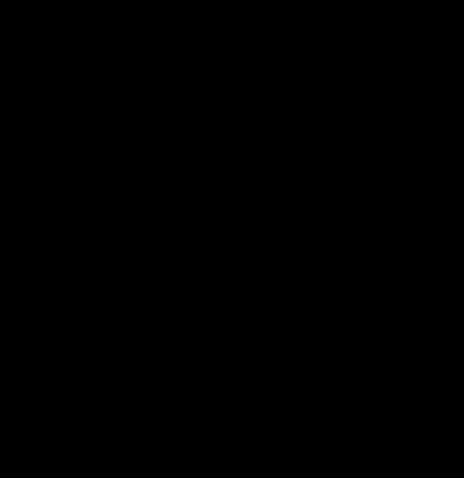

In [10]:
diagrams.along_lines_and_split()

In [11]:
pieces = uws.split_lines(segments, districts, zone_id="district_id")
heat_pieces = uws.along_lines(heat, pieces, [
    uw.weighted_mean("utci", as_="utci_mean", weighted_total_as="utci_m", valid_measure_as="valid_m"),
    uw.max("utci", as_="utci_max"),
])
heat_pieces[["piece_id", "length_m", "utci_mean", "utci_max", "valid_fraction"]].round(2).head()

,piece_id,length_m,utci_mean,utci_max,valid_fraction
0,1-2-0|MD,250.0,27.13,27.88,1.0
1,1-10-0|MD,250.0,<NA>,<NA>,0.0
2,2-3-0|MD,250.0,27.3,27.75,1.0
3,11-2-0|MD,250.0,27.37,27.78,1.0
4,3-4-0|MD,250.0,27.39,27.81,1.0


In [12]:
by_district = uws.reduce(heat_pieces, by="zone_id", targets=districts, target_id="district_id",
                         reductions=[uws.ratio_of_sums("utci_m", "valid_m", as_="street_utci")])
by_district[["name", "street_utci"]].round(2)

,name,street_utci
0,Northgate,28.53
1,Old Town,32.83
2,Eastfield,29.67
3,Mill District,29.04
4,Riverside,28.13


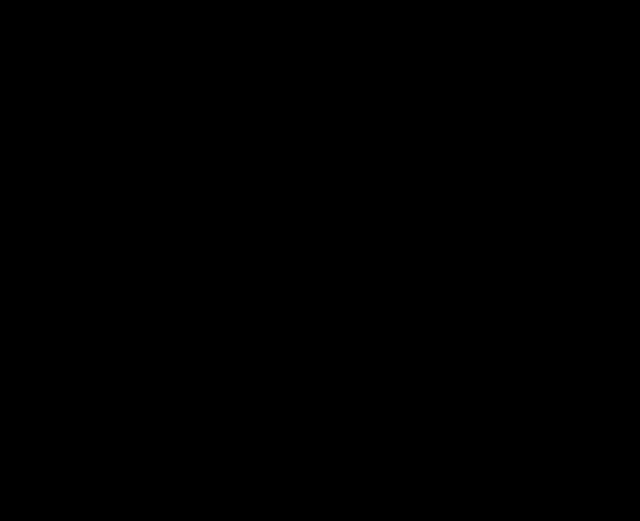

In [13]:
(Map("UTCI along the streets")
 .lines(heat_pieces, "utci_mean", legend="mean UTCI along each street piece (°C)", width=3.2, classes=6,
        tooltip=["length_m", "valid_fraction"])
 .outline(districts, label="name", width=1)
 .note("Dashed: no valid UTCI (the sensor gap in Eastfield, and the southern edge)."))

**Next:** [7. Plans and replay](07_plans_and_replay.ipynb).